# Como baixar dados de cripto direto da fonte?

**Python Finance Lab · Aula 7**

## Parte 1 · A pergunta

### Bloco 1 · Abertura

Na aula 5, estudamos a diversificação em um universo finito de ações. A evidência daquele experimento não identifica um piso universal de risco de mercado e não garante que adicionar qualquer ativo reduza o risco. Na aula 8, vamos investigar o que uma pequena parcela de Bitcoin faz naquela carteira, sem antecipar a conclusão.

Antes, precisamos dos dados. Nesta aula, usamos a API pública de mercado da Binance Spot, sem cadastro nem chave para estes endpoints. Trabalhamos somente com dados: nenhuma compra ou venda é enviada.[7]

Vamos enviar parâmetros, ler JSON, converter datas em milissegundos e buscar páginas de candles. No fim, salvamos arquivos locais para estudar sem depender de uma nova coleta. Conteúdo exclusivamente educacional; não constitui recomendação de investimento.

## Parte 2 · Conceitos

### Bloco 2 · O vocabulário da aula

**Corretora e fonte de preços.** Uma corretora reúne ordens de compradores e vendedores. O histórico desta aula representa negócios da Binance Spot; não é um preço único de todo o mercado.

**Par de negociação.** BTCUSDT é Bitcoin cotado em USDT: o preço diz quantos USDT custa um bitcoin. ETHUSDT segue a mesma lógica. Volume-base é quantidade de BTC ou ETH, não quantidade de USDT.

**Stablecoin.** USDT é uma stablecoin que busca manter paridade com o dólar americano. Isso é um objetivo, não uma garantia; USDT não é USD. Não convertemos esta análise para dólares nem reais.

**Candle OHLCV.** Um candle resume abertura, máxima, mínima, fechamento e volume de um período. A resposta também informa os timestamps de abertura e fechamento, o volume no ativo de cotação, a quantidade de negócios e campos de compras tomadoras.[6]

**Mercado 24/7.** Um ano civil tem 365 ou 366 dias. Adotamos 365 como convenção fixa de anualização da volatilidade de retornos diários de cripto; isso não afirma que todo ano tenha 365 candles.

**Horário UTC.** Sem o parâmetro timeZone, os candles usam UTC. O índice de nossa tabela é a abertura do candle, não o instante em que seu fechamento se tornou conhecido. O candle rotulado 2021-10-01 abre em 01/10, 00:00 UTC, e seu close pertence ao fim desse mesmo dia UTC.[6]

No período estudado, Brasília está em UTC−3: a abertura de 01/10, 00:00 UTC, corresponde a 30/09, 21:00 em Brasília. Os brutos retornados registram o fechamento diário em 23:59:59.999 UTC, isto é, 20:59:59.999 em Brasília; a fronteira do dia seguinte é 00:00:00.000 UTC, ou 21:00. Não confundimos esses instantes nem tratamos o close como informação disponível na abertura.

**API REST, parâmetros e paginação.** Os parâmetros selecionam símbolo, intervalo e datas. O endpoint devolve até 1.000 candles por GET. Para estes 1.826 dias, a coleta validada usa duas páginas não vazias por par, de 1.000 e 826 candles. A versão corrigida encerra após a página curta; não faz a consulta vazia terminal que existia no laço original.[6]

## Parte 3 · Fórmulas

### Bloco 3 · As contas da aula

**Datas em milissegundos.** A API usa, por padrão, timestamps em milissegundos. A data inicial equivale a 1.633.046.400.000 ms desde 01/01/1970, 00:00 UTC, conforme o código e a resposta capturada.[6]

$$t_{\mathrm{ms}}=1000\times(\text{segundos desde 01/01/1970, 00:00 UTC})$$

Um dia tem 86.400.000 ms. De 01/10/2021 a 30/09/2026, inclusive, esperamos **1826 candles**, incluindo 29/02/2024. Entre o primeiro e o último fechamento há **1.825 intervalos diários**: o número de observações não é o número de retornos.

**Volatilidade anual.** Mantemos retornos simples consecutivos e desvio padrão amostral (ddof=1), multiplicado pela raiz da convenção anual:

$$\sigma_{anual}=s(r_{diários})\sqrt{365}.$$

Um desvio diário de 3% resultaria em 57,3% pela convenção 365, ou 47,6% com 252. A razão entre escalas é 1,2035, cerca de 20,35% a mais; não são pontos percentuais fixos.

**Retorno e queda.** O crescimento é fechamento final dividido pelo inicial. O CAGR mantém a fórmula original com dias corridos divididos por **365,25**; não substituímos esse fator por 365. A queda máxima usa o menor valor de fechamento dividido pelo máximo de fechamentos acumulado menos um. Não usamos máximas ou mínimas intradiárias para essa medida.

## Parte 4 · Implementação

### Bloco 4 · Importar as bibliotecas

Importamos requests para HTTP, pandas para as tabelas, Matplotlib para a comparação histórica e plotly.graph_objects para os candles interativos. O ambiente testado e as versões estão em `requirements.txt` e `AMBIENTE_VERIFICADO.json`.

Se precisar instalar no seu Jupyter, use `%pip install requests pandas matplotlib plotly kaleido ipykernel`; para exportar PNG com Kaleido também é necessário Chrome/Chromium. Esta instalação não é uma célula curricular nem foi simulada. A exportação desta produção usou Chrome real e a variável BROWSER_PATH somente no processo; a figura interativa foi preservada.[3]

> **O que apareceu:** Nada: imports sem saída é o comportamento correto.

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

### Bloco 5 · As premissas

Declaramos o endpoint público de dados de mercado, os dois pares Spot, os candles de um dia e o período inclusivo em UTC. O endereço data-api.binance.vision serve dados públicos sem autenticação. Disponibilidade na sua região ou rede não é garantida: se houver bloqueio, use a reprodução local rotulada, sem contornar controles de acesso.[7]

O intervalo é sensível a maiúsculas e minúsculas: 1d significa um dia; 1w é uma semana; 1M é um mês. Não alteramos o intervalo nesta coleta.[6]

> **O que apareceu:** Nada: são atribuições, sem saída inventada.

In [3]:
BASE_URL = "https://data-api.binance.vision"
PARES = ["BTCUSDT", "ETHUSDT"]
INTERVALO = "1d"
DATA_INICIO = "2021-10-01"
DATA_FIM = "2026-09-30"

### Bloco 6 · Uma chamada de um dia só

Antes de paginar, pedimos um candle de BTCUSDT. Criamos o timestamp UTC, passamos os parâmetros em um dicionário e deixamos requests montar a URL. O timeout limita a espera; raise_for_status interrompe erros HTTP, mas não substitui a validação do conteúdo JSON.

Na coleta original, URL efetiva, status, horários, corpo bruto e SHA-256 foram preservados. O código abaixo ensina um GET público normal. Nesta V2, a validação executou esse código com replay privado do corpo real capturado, sem rede; não é uma nova consulta ao mercado. O adaptador não acompanha as células do aluno e não fabrica preços.

> **O que apareceu:** O candle real de 01/10/2021 fechou em **48.141,61 USDT por BTC**. A primeira abertura retornada foi 1633046400000 ms; o JSON bruto tem uma linha com 12 campos.

In [4]:
inicio_ms = int(pd.Timestamp(DATA_INICIO, tz="UTC").timestamp() * 1000)
print("Início em milissegundos:", inicio_ms)

parametros = {"symbol": "BTCUSDT", "interval": INTERVALO, "startTime": inicio_ms, "limit": 1}
resposta = requests.get(f"{BASE_URL}/api/v3/klines", params=parametros, timeout=30)
resposta.raise_for_status()

print(resposta.url)
resposta.json()

Início em milissegundos: 1633046400000
https://data-api.binance.vision/api/v3/klines?symbol=BTCUSDT&interval=1d&startTime=1633046400000&limit=1


[[1633046400000,
  '43820.01000000',
  '48495.00000000',
  '43283.03000000',
  '48141.61000000',
  '66244.87492000',
  1633132799999,
  '3076094886.59247420',
  1771237,
  '34156.88321000',
  '1585411525.33782700',
  '0']]

**Depois de rodar — resultado da reexecução V2 do snapshot.** O candle real de 01/10/2021 fechou em **48.141,61 USDT por BTC**. A primeira abertura retornada foi 1633046400000 ms; o JSON bruto tem uma linha com 12 campos.

### Bloco 7 · O que significa cada item

A resposta contém uma lista por candle, com 12 posições. Nomeamos os campos conforme a documentação: abertura em ms; preços de abertura, máxima, mínima e fechamento; volume-base; fechamento em ms; volume em USDT; quantidade de negócios; volumes tomadores de compra-base e compra-USDT; e um campo ignorado.[6]

Preços e volumes chegam como strings e ainda não estão prontos para cálculos. Em pandas 3, a representação de texto pode aparecer como str em vez de object. Os dois formatos são texto; a conversão numérica será explícita.

> **O que apareceu:** Tipos das primeiras seis colunas e uma tabela real de uma linha com os 12 campos.

In [5]:
COLUNAS = [
    "abertura_ms", "abertura", "maxima", "minima", "fechamento", "volume",
    "fechamento_ms", "volume_usdt", "negocios", "compra_base", "compra_usdt", "ignorar",
]

um_candle = pd.DataFrame(resposta.json(), columns=COLUNAS)
print(um_candle.dtypes.head(6))
um_candle

abertura_ms    int64
abertura         str
maxima           str
minima           str
fechamento       str
volume           str
dtype: object


,abertura_ms,abertura,maxima,minima,fechamento,volume,fechamento_ms,volume_usdt,negocios,compra_base,compra_usdt,ignorar
0,1633046400000,43820.01000000,48495.00000000,43283.03000000,48141.61000000,66244.87492000,1633132799999,3076094886.59247420,1771237,34156.88321000,1585411525.33782700,0


### Bloco 8 · A função que organiza os candles

A função organizar_candles monta a tabela com os 12 nomes, converte abertura_ms com unit="ms" e utc=True, converte OHLCV para float e mantém cinco colunas numéricas.

A coluna data torna-se o índice e continua representando a **abertura**. O fechamento rotulado com essa data é o último preço do mesmo candle diário, não o preço da abertura. O teste visível usa o exemplo de 01/10/2021. Na mesma célula, a função `validar_candles` rejeita tabela vazia, datas sem UTC, repetição, desordem, NaN, infinitos, preços não positivos, volume negativo e máximas/mínimas incoerentes. `organizar_candles` rejeita resposta vazia e estrutura inválida, converte os dados e chama essa guarda antes de retornar. A cobertura diária e a meia-noite exata são exigidas no bloco 9, antes de gráficos e métricas; os blocos 15 e 16 repetem as conferências para ensinar a lê-las.

> **O que apareceu:** Uma tabela OHLCV numérica, índice 2021-10-01 00:00:00+00:00.

In [6]:
def validar_candles(tabela, inicio=None, fim=None, intervalo=None):
    """Rejeita dados inválidos antes de gráficos, contas ou arquivos."""
    precos = ["abertura", "maxima", "minima", "fechamento", "volume"]
    if not isinstance(tabela, pd.DataFrame) or tabela.empty:
        raise ValueError("Tabela vazia: nenhum candle disponível")
    if list(tabela.columns) != precos:
        raise ValueError("A tabela deve conter somente os cinco campos OHLCV")
    if not isinstance(tabela.index, pd.DatetimeIndex) or str(tabela.index.tz) != "UTC":
        raise ValueError("O índice dos candles deve conter datas em UTC")
    if tabela.index.hasnans or not tabela.index.is_unique or not tabela.index.is_monotonic_increasing:
        raise ValueError("Datas ausentes, duplicadas ou fora de ordem")
    if any(not pd.api.types.is_numeric_dtype(tabela[c]) for c in precos):
        raise ValueError("Os cinco campos OHLCV devem ser numéricos")
    if tabela.isna().any().any() or tabela.isin([float("inf"), float("-inf")]).any().any():
        raise ValueError("OHLCV contém valor ausente ou infinito")
    ohlc = tabela[["abertura", "maxima", "minima", "fechamento"]]
    if not (ohlc > 0).all().all() or not (tabela["volume"] >= 0).all():
        raise ValueError("Preços devem ser positivos e volume não pode ser negativo")
    if not (tabela["maxima"] >= ohlc.max(axis=1)).all() or not (tabela["minima"] <= ohlc.min(axis=1)).all():
        raise ValueError("Máxima ou mínima inconsistente com os preços OHLC")
    if inicio is not None or fim is not None:
        if inicio is None or fim is None:
            raise ValueError("Informe tanto a data inicial quanto a data final")
        inicio_utc = pd.Timestamp(inicio, tz="UTC")
        fim_exclusivo = pd.Timestamp(fim, tz="UTC") + pd.Timedelta(days=1)
        if inicio_utc >= fim_exclusivo:
            raise ValueError("A data inicial não pode ser posterior à data final")
        if ((tabela.index < inicio_utc) | (tabela.index >= fim_exclusivo)).any():
            raise ValueError("Há abertura de candle fora do período solicitado")
        if intervalo == "1d":
            esperados = pd.date_range(inicio_utc, fim_exclusivo, freq="D", inclusive="left")
            if not (tabela.index == tabela.index.normalize()).all():
                raise ValueError("Candles diários devem abrir exatamente à meia-noite UTC")
            if len(esperados.difference(tabela.index)) or len(tabela.index.difference(esperados)):
                raise ValueError("Calendário diário incompleto: há dias faltantes ou extras")
            if fim_exclusivo > pd.Timestamp.now(tz="UTC"):
                raise ValueError("O período diário solicitado ainda não terminou")
    return tabela


def organizar_candles(linhas):
    """Converte a estrutura da Binance e valida os dados antes de devolvê-los."""
    if not isinstance(linhas, list) or not linhas:
        raise ValueError("Resposta vazia ou inválida: nenhum candle recebido")
    for candle in linhas:
        if not isinstance(candle, list) or len(candle) != 12:
            raise ValueError("Cada candle deve ter 12 campos")
        if not isinstance(candle[0], int) or isinstance(candle[0], bool):
            raise ValueError("A abertura deve ser um timestamp inteiro em milissegundos")
    tabela = pd.DataFrame(linhas, columns=COLUNAS)
    tabela["data"] = pd.to_datetime(tabela["abertura_ms"], unit="ms", utc=True)
    precos = ["abertura", "maxima", "minima", "fechamento", "volume"]
    try:
        tabela[precos] = tabela[precos].astype(float)
    except (ValueError, TypeError) as erro:
        raise ValueError("OHLCV deve conter números válidos") from erro
    return validar_candles(tabela.set_index("data")[precos])


organizar_candles(resposta.json())

,abertura,maxima,minima,fechamento,volume
data,,,,,
2021-10-01 00:00:00+00:00,43820.01,48495.0,43283.03,48141.61,66244.87492


### Bloco 9 · Buscando em páginas, com while

O laço while repete enquanto a próxima abertura pedida não passa do fim. Construímos fim_ms como a meia-noite seguinte à data final menos um milissegundo. A API limita aberturas por startTime e endTime; isso não deve ser confundido com a garantia de que todo intervalo retornado já acabou, especialmente em candles semanais.[6]

No modo ao vivo, a função envia GETs normais. Antes do primeiro GET, rejeita início posterior ao fim com ValueError em português. Cada página deve ser uma lista de candles de 12 campos, com aberturas dentro do intervalo e em ordem estrita; a guarda de avanço impede regressão da paginação. O próximo pedido começa um milissegundo após a última abertura. Uma página curta encerra sem GET vazio terminal. Uma resposta inicial vazia não é sucesso: ao organizar, a função rejeita a ausência de candles. Se uma página vazia encerrar uma coleta parcial, a cobertura diária incompleta também é rejeitada antes do retorno.

Antes de devolver a tabela, `validar_candles` confere o período e, exclusivamente para intervalo `1d`, todos os dias esperados, a meia-noite UTC exata e o término do período. Assim, os blocos 11–13 não recebem dados que falharam nesse contrato. Para `1h` e `1w`, permanecem as guardas de valores, UTC, ordem e limites de abertura, mas não aplicamos um calendário diário nem afirmamos que as semanas estão completas: esse filtro é explicado no exercício. Nesta reexecução do snapshot foram consumidas duas páginas reais preservadas por par, de **1.000 + 826 candles**, sem consulta de rede nem página vazia terminal.

> **O que apareceu:** Nada: a função foi definida. Chamá-la no notebook ao vivo pode acessar a rede; as saídas salvas nesta entrega são de replay do snapshot.

In [7]:
def baixar_candles(par, inicio, fim, intervalo="1d"):
    """Baixa todos os candles de um par entre duas datas, em páginas de até 1.000."""
    inicio_ms = int(pd.Timestamp(inicio, tz="UTC").timestamp() * 1000)
    fim_ms = int((pd.Timestamp(fim, tz="UTC") + pd.Timedelta(days=1)).timestamp() * 1000) - 1
    if pd.Timestamp(inicio, tz="UTC") > pd.Timestamp(fim, tz="UTC"):
        raise ValueError("A data inicial não pode ser posterior à data final")
    linhas = []

    while inicio_ms <= fim_ms:
        parametros = {
            "symbol": par, "interval": intervalo,
            "startTime": inicio_ms, "endTime": fim_ms, "limit": 1000,
        }
        resposta = requests.get(f"{BASE_URL}/api/v3/klines", params=parametros, timeout=30)
        resposta.raise_for_status()
        pagina = resposta.json()
        if not isinstance(pagina, list):
            raise ValueError("A API deve devolver uma lista de candles")
        if len(pagina) == 0:
            break
        anterior_ms = inicio_ms - 1
        for candle in pagina:
            if not isinstance(candle, list) or len(candle) != 12:
                raise ValueError("Cada candle deve ter 12 campos")
            abertura_ms = candle[0]
            if not isinstance(abertura_ms, int) or not inicio_ms <= abertura_ms <= fim_ms:
                raise ValueError("Abertura fora do intervalo solicitado")
            if abertura_ms <= anterior_ms:
                raise ValueError("Candles fora de ordem ou duplicados; sem avanço")
            anterior_ms = abertura_ms
        proximo_ms = pagina[-1][0] + 1
        if proximo_ms <= inicio_ms:
            raise ValueError("Paginação sem avanço")
        linhas = linhas + pagina
        inicio_ms = proximo_ms
        print(f"{par}: {len(pagina)} candles nesta página, {len(linhas)} no total")
        if len(pagina) < 1000:
            break

    tabela = organizar_candles(linhas)
    return validar_candles(tabela, inicio, fim, intervalo)

### Bloco 10 · BTC e ETH de 2021 a 2026

Guardamos as tabelas em um dicionário, com os pares como chaves. Para cada par, o log desta reexecução do snapshot mostra 1.000 candles e depois 826, totalizando 1.826 observações já aprovadas pela guarda preventiva. A última data rotulada é 30/09/2026, abertura às 00:00 UTC; não é a hora em que o fechamento se tornou disponível.

O dicionário permite usar o mesmo código para ambos os pares, sem duplicar cálculos nem misturar as unidades dos volumes-base.

> **O que apareceu:** Foram **1.826 candles por par**. Fechamentos de 30/09/2026: **BTC 83.623,60 USDT** e **ETH 2.686,01 USDT**. O replay completo leu duas páginas capturadas por par e não fez chamada vazia terminal nem GET real.

In [8]:
candles = {}
for par in PARES:
    candles[par] = baixar_candles(par, DATA_INICIO, DATA_FIM, INTERVALO)

btc = candles["BTCUSDT"]
print()
print("Candles de BTC:", len(btc), "| primeiro:", btc.index[0].date(), "| último:", btc.index[-1].date())
btc.tail()

BTCUSDT: 1000 candles nesta página, 1000 no total
BTCUSDT: 826 candles nesta página, 1826 no total
ETHUSDT: 1000 candles nesta página, 1000 no total
ETHUSDT: 826 candles nesta página, 1826 no total

Candles de BTC: 1826 | primeiro: 2021-10-01 | último: 2026-09-30


,abertura,maxima,minima,fechamento,volume
data,,,,,
2026-09-26 00:00:00+00:00,84100.00,84473.58,83798.00,84433.10,8058.06465
2026-09-27 00:00:00+00:00,84433.11,85159.03,84132.00,84472.00,9615.12963
2026-09-28 00:00:00+00:00,84472.01,84999.00,82563.00,83500.01,20960.72462
2026-09-29 00:00:00+00:00,83500.01,84563.99,82775.94,83663.66,13461.55331
2026-09-30 00:00:00+00:00,83663.66,85649.95,82956.11,83623.60,18522.82001


**Depois de rodar — resultado da reexecução V2 do snapshot.** Foram **1.826 candles por par**. Fechamentos de 30/09/2026: **BTC 83.623,60 USDT** e **ETH 2.686,01 USDT**. O replay completo leu duas páginas capturadas por par e não fez chamada vazia terminal nem GET real.

### Bloco 11 · O gráfico de candles

O corpo da vela liga abertura e fechamento; os pavios marcam máxima e mínima. A alta usa verde escuro #157347 e a queda vermelho #B23A48. O fundo claro de papel, as fontes e as margens estão explícitos no código, não em um redesenho posterior.

Recortamos de 01/04 a 30/09/2026: são **183 velas**, não uma amostra fictícia de cerca de 180 dias. go.Candlestick recebe as quatro séries OHLC e o índice de abertura UTC. A largura de 1.500 px e altura de 760 px, títulos 24 e ticks 18 favorecem leitura no material audiovisual.

fig.show exibe o gráfico interativo. A produção capturou image/png e o MIME Plotly na mesma execução de kernel, além de exportar JSON e HTML autocontido da mesma figura. Os arquivos estão em `figuras/`; não houve recriação externa do gráfico.

> **O que apareceu:** Entre os fechamentos de 01/04 e 30/09/2026, BTC variou **22,77%**, com quedas e recuperações no caminho. A maior amplitude absoluta máxima−mínima ocorreu em **2026-09-21**: **6.545,45 USDT**, entre mínima **80.850,22** e máxima **87.395,67 USDT**. Amplitude não é retorno diário nem desvio padrão.

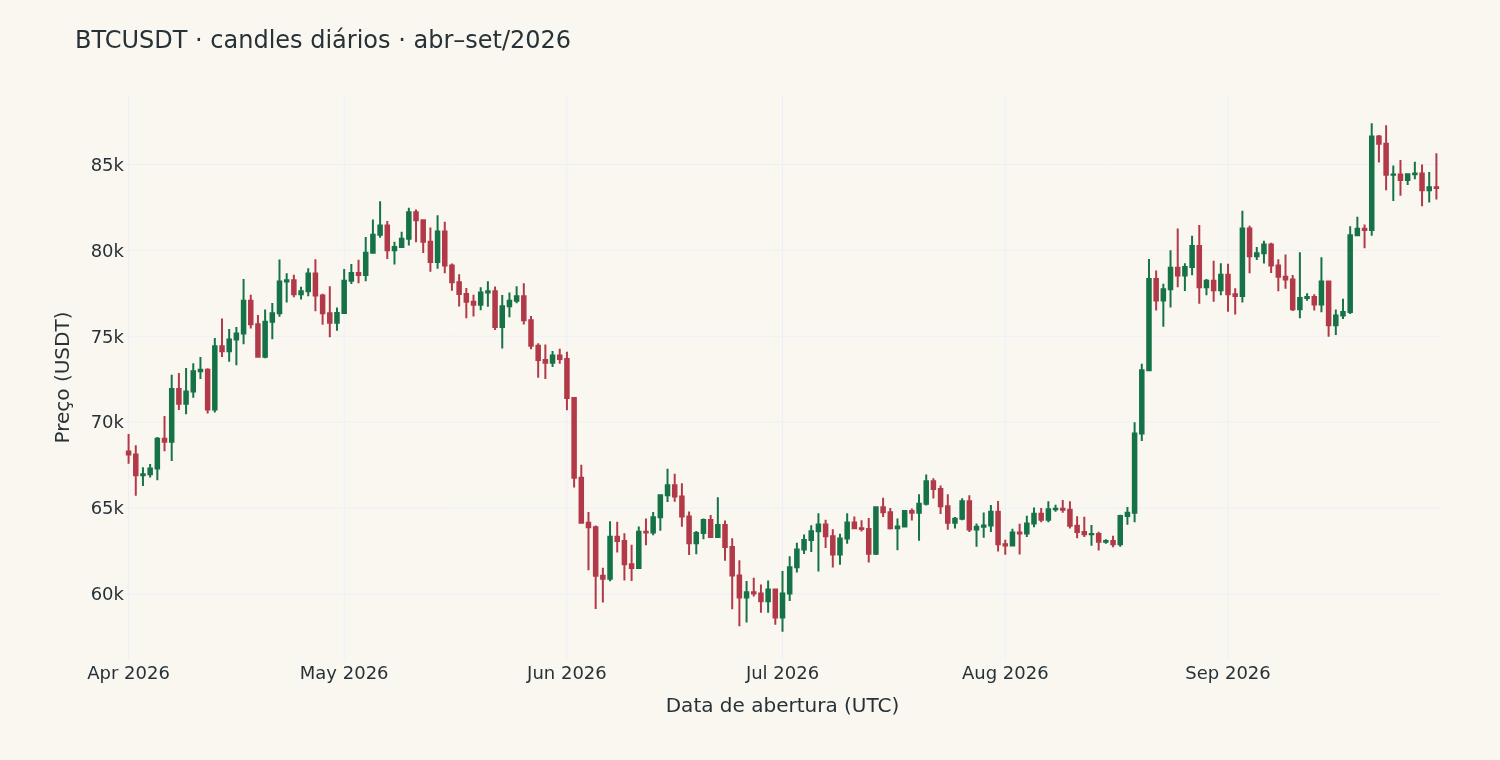

In [9]:
ultimos = btc.loc["2026-04-01":]

fig = go.Figure(
    data=[
        go.Candlestick(
            x=ultimos.index,
            open=ultimos["abertura"],
            high=ultimos["maxima"],
            low=ultimos["minima"],
            close=ultimos["fechamento"],
            name="BTCUSDT",
            increasing_line_color="#157347",
            increasing_fillcolor="#157347",
            decreasing_line_color="#B23A48",
            decreasing_fillcolor="#B23A48",
        )
    ]
)
fig.update_layout(
    title=dict(text="BTCUSDT · candles diários · abr–set/2026", font=dict(size=24)),
    yaxis_title="Preço (USDT)",
    xaxis_title="Data de abertura (UTC)",
    xaxis_rangeslider_visible=False,
    template="plotly_white",
    paper_bgcolor="#FAF7F0",
    plot_bgcolor="#FAF7F0",
    font=dict(family="DejaVu Sans, sans-serif", size=20, color="#263238"),
    width=1500,
    height=760,
    margin=dict(l=125, r=60, t=95, b=100),
)
fig.update_xaxes(tickfont=dict(size=18), title_font=dict(size=20), automargin=True)
fig.update_yaxes(tickfont=dict(size=18), title_font=dict(size=20), automargin=True)
fig.show()

**Depois de rodar — resultado da reexecução V2 do snapshot.** Entre os fechamentos de 01/04 e 30/09/2026, BTC variou **22,77%**, com quedas e recuperações no caminho. A maior amplitude absoluta máxima−mínima ocorreu em **2026-09-21**: **6.545,45 USDT**, entre mínima **80.850,22** e máxima **87.395,67 USDT**. Amplitude não é retorno diário nem desvio padrão.

### Bloco 12 · Cinco anos de BTC e ETH

Para comparar os preços em escalas diferentes, dividimos cada fechamento pelo primeiro. As curvas partem de 1 e representam o valor bruto hipotético de **1 USDT**, mantendo a quantidade comprada de cada cripto sem custos. Não representam um investimento de 1 dólar nem garantem conversibilidade de USDT para USD.

BTC fica em âmbar escuro #9A6500 e ETH em roxo #6F48C9. As linhas contínua e tracejada também distinguem os pares. Títulos, eixos, ticks, legenda e tamanho são definidos no código executado; a figura PNG foi capturada inline pelo Matplotlib.

> **O que apareceu:** No final, 1 USDT correspondeu a **1,7370 USDT em BTC** ou **0,8115 USDT em ETH**. Os maiores drawdowns de fechamentos tiveram fundos em **2022-11-21** e **2022-06-18**, respectivamente; não inferimos magnitude relativa a outras aulas sem uma comparação compatível.

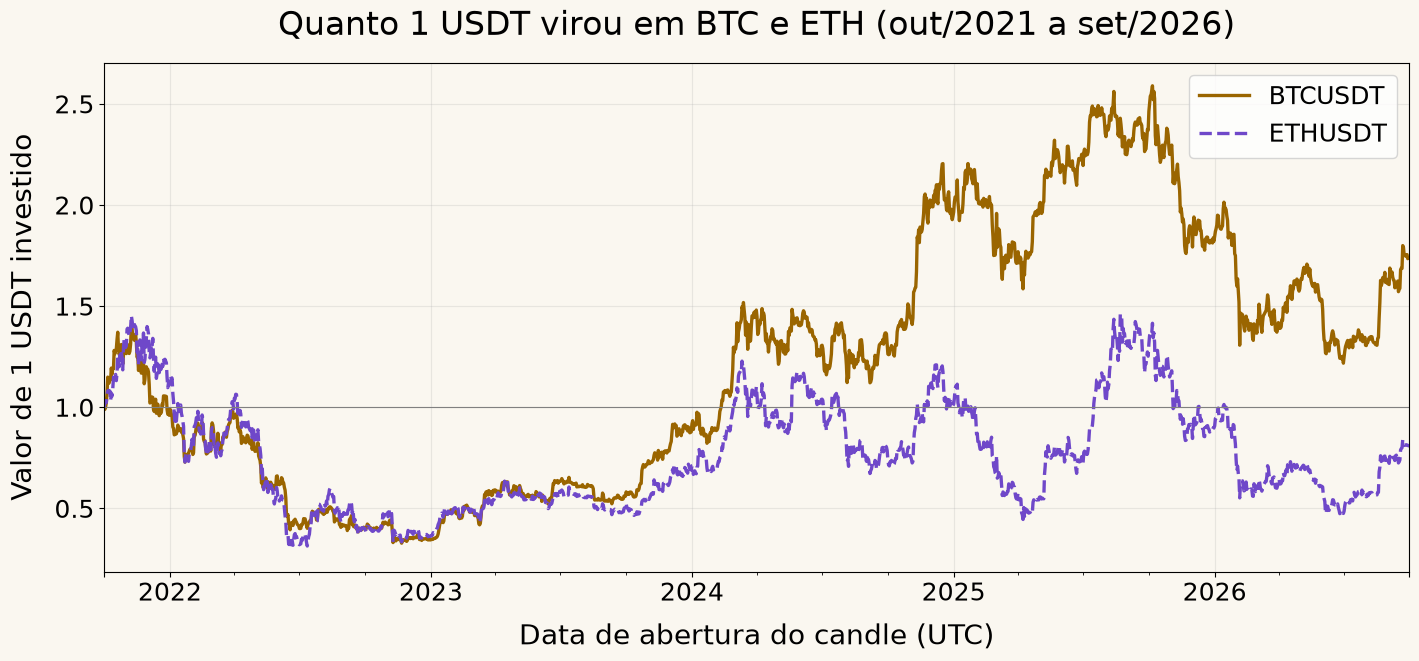

In [10]:
crescimento = pd.DataFrame()
for par, tabela in candles.items():
    crescimento[par] = tabela["fechamento"] / tabela["fechamento"].iloc[0]

ax = crescimento.plot(
    figsize=(15, 7.6),
    style=["-", "--"],
    color=["#9A6500", "#6F48C9"],
    linewidth=2.4,
    title="Quanto 1 USDT virou em BTC e ETH (out/2021 a set/2026)",
)
ax.figure.set_dpi(100)
ax.figure.set_facecolor("#FAF7F0")
ax.set_facecolor("#FAF7F0")
ax.set_title(ax.get_title(), fontsize=24, pad=20)
ax.axhline(1, color="gray", linewidth=0.8)
ax.set_ylabel("Valor de 1 USDT investido", fontsize=20, labelpad=12)
ax.set_xlabel("Data de abertura do candle (UTC)", fontsize=20, labelpad=12)
ax.tick_params(axis="both", labelsize=18)
ax.legend(fontsize=18)
ax.grid(alpha=0.25)
ax.figure.subplots_adjust(left=0.10, right=0.97, bottom=0.20, top=0.87)
plt.show()

**Depois de rodar — resultado da reexecução V2 do snapshot.** No final, 1 USDT correspondeu a **1,7370 USDT em BTC** ou **0,8115 USDT em ETH**. Os maiores drawdowns de fechamentos tiveram fundos em **2022-11-21** e **2022-06-18**, respectivamente; não inferimos magnitude relativa a outras aulas sem uma comparação compatível.

### Bloco 13 · Retorno e risco, com as funções da aula 2

Mantemos as funções financeiras originais. retorno_anual usa CAGR pelos dias transcorridos/365,25. volatilidade_anual calcula pct_change, remove o primeiro retorno ausente e usa o desvio padrão amostral padrão do pandas, anualizando por 365 para cripto. queda_maxima mede a queda do fechamento frente ao pico acumulado de fechamentos.

A coluna com 252 é uma **escala alternativa para demonstrar a convenção**, não a prova de que o ativo mudou de risco. Ambas partem da mesma série diária e sua razão é a raiz de 365/252. Não adicionamos Sharpe nem alteramos o método financeiro desta aula.

> **O que apareceu:** Pela convenção 365, volatilidade anual: **BTC 51,29%**; **ETH 68,87%**. Drawdowns: **-76,63%** e **-79,30%**. A comparação com a carteira da aula 2 está pendente de período e método compatíveis; não baixamos suas cotações.

In [11]:
def retorno_anual(serie):
    """Retorno médio por ano, com juros compostos (anos contados em dias corridos)."""
    anos = (serie.index[-1] - serie.index[0]).days / 365.25
    return (serie.iloc[-1] / serie.iloc[0]) ** (1 / anos) - 1


def volatilidade_anual(serie, periodos_por_ano=252):
    """Desvio padrão dos retornos, levado para a escala de um ano."""
    return serie.pct_change().dropna().std() * periodos_por_ano ** 0.5


def queda_maxima(serie):
    """A pior queda do período, do pico ao fundo."""
    return (serie / serie.cummax() - 1).min()


risco = pd.DataFrame(index=PARES)
for par, tabela in candles.items():
    fechamento = tabela["fechamento"]
    risco.loc[par, "Retorno total (%)"] = (fechamento.iloc[-1] / fechamento.iloc[0] - 1) * 100
    risco.loc[par, "Retorno ao ano (%)"] = retorno_anual(fechamento) * 100
    risco.loc[par, "Volatilidade com 365 dias (%)"] = volatilidade_anual(fechamento, 365) * 100
    risco.loc[par, "Volatilidade com 252 dias (%)"] = volatilidade_anual(fechamento, 252) * 100
    risco.loc[par, "Queda máxima (%)"] = queda_maxima(fechamento) * 100

risco.round(2)

,Retorno total (%),Retorno ao ano (%),Volatilidade com 365 dias (%),Volatilidade com 252 dias (%),Queda máxima (%)
BTCUSDT,73.70,11.68,51.29,42.62,-76.63
ETHUSDT,-18.85,-4.09,68.87,57.22,-79.30


**Depois de rodar — resultado da reexecução V2 do snapshot.** Pela convenção 365, volatilidade anual: **BTC 51,29%**; **ETH 68,87%**. Drawdowns: **-76,63%** e **-79,30%**. A comparação com a carteira da aula 2 está pendente de período e método compatíveis; não baixamos suas cotações.

### Bloco 14 · Salvando em CSV

CSV é texto tabular portátil. Os nomes relativos gravam no **diretório de trabalho do kernel**, que não é automaticamente a pasta do notebook. Nesta validação, os dois diretórios foram explicitamente igualados; ao executar no seu Jupyter, confira o diretório de trabalho antes de salvar. Antes de qualquer `to_csv`, revalidamos **todos os pares**; se qualquer tabela falhar, nenhum dos dois CSVs é substituído por esta célula. Essa proteção cobre falhas de validação, não promete uma transação atômica contra erro de disco, interrupção ou crash durante as escritas.

Na leitura, float_precision="round_trip" seleciona o conversor de ida e volta do pandas. Isso evita perdas de representação observadas no teste com floats sensíveis; igualdade não é uma promessa universal para qualquer parser de planilha.[4]

Explicitamos também a resolução temporal em milissegundos com as_unit("ms"). No pandas testado, o índice criado da API era datetime64[ms, UTC], enquanto o leitor CSV escolhia microssegundos. A primeira execução expôs essa diferença de dtype; um teste de regressão falhou antes da correção. Normalizar a resolução não desloca datas nem altera preços. O bloco 17 confere os índices e os cinco campos de ambos os pares, não só o fechamento do BTC.

> **O que apareceu:** Duas mensagens Salvo e as três primeiras linhas do CSV BTC, relidas com round_trip.

In [12]:
# Primeiro validar TODOS os pares; só depois iniciar qualquer escrita.
if set(candles) != set(PARES):
    raise ValueError("Os pares disponíveis não correspondem a PARES")
for par in PARES:
    validar_candles(candles[par], DATA_INICIO, DATA_FIM, INTERVALO)

for par, tabela in candles.items():
    nome = f"candles_{par}_{INTERVALO}.csv"
    tabela.to_csv(nome)
    print("Salvo:", nome)

relido = pd.read_csv(
    f"candles_BTCUSDT_{INTERVALO}.csv", index_col="data", parse_dates=True,
    float_precision="round_trip",
)
relido.index = relido.index.as_unit("ms")
relido.head(3)

Salvo: candles_BTCUSDT_1d.csv
Salvo: candles_ETHUSDT_1d.csv


,abertura,maxima,minima,fechamento,volume
data,,,,,
2021-10-01 00:00:00+00:00,43820.01,48495.00,43283.03,48141.61,66244.87492
2021-10-02 00:00:00+00:00,48141.60,48336.59,47430.18,47634.90,30508.98131
2021-10-03 00:00:00+00:00,47634.89,49228.08,47088.00,48200.01,30825.05601


## Parte 5 · Validação

### Bloco 15 · Nenhum dia faltando, extra ou repetido

Construímos todos os dias UTC esperados. Verificamos faltantes e extras nos dois sentidos, unicidade, ordem crescente, ausência de NaN e infinitos, preços OHLC estritamente positivos, volume não negativo e coerência das máximas e mínimas em cada linha.

Esta é uma **rechecagem pedagógica**, não a primeira guarda. O contrato já foi verificado na carga, antes de qualquer gráfico ou conta, e novamente para todos os pares antes das gravações. Os asserts mostram como conferir cada condição: imprimir uma contagem não basta. Também exigimos que o período civil tenha terminado. A auditoria V2 leu o relógio e os fechamentos dos brutos preservados e verificou que todos os fechamentos precedem o horário do servidor da coleta original; não consultou um novo relógio de rede.

> **O que apareceu:** 1.826 esperados; ambos os pares têm 1.826, faltantes 0, extras 0, sem repetição True; integridade OK.

In [13]:
esperados = pd.date_range(DATA_INICIO, DATA_FIM, freq="D", tz="UTC")
print("Candles esperados:", len(esperados))
assert esperados[-1] + pd.Timedelta(days=1) <= pd.Timestamp.now(tz="UTC"), "O período ainda não terminou"

for par, tabela in candles.items():
    faltando = esperados.difference(tabela.index)
    extras = tabela.index.difference(esperados)
    print(f"{par}: {len(tabela)} candles | faltando: {len(faltando)} | extras: {len(extras)} | sem repetição: {tabela.index.is_unique}")
    assert len(faltando) == 0 and len(extras) == 0, f"{par}: datas fora do contrato"
    assert tabela.index.is_unique and tabela.index.is_monotonic_increasing, f"{par}: repetição ou desordem"
    assert not tabela.isna().any().any(), f"{par}: valor ausente"
    assert not tabela.isin([float("inf"), float("-inf")]).any().any(), f"{par}: valor infinito"
    ohlc = tabela[["abertura", "maxima", "minima", "fechamento"]]
    assert (ohlc > 0).all().all(), f"{par}: preço não positivo"
    assert (tabela["volume"] >= 0).all(), f"{par}: volume negativo"
    assert (tabela["maxima"] >= ohlc.max(axis=1)).all(), f"{par}: máxima inconsistente"
    assert (tabela["minima"] <= ohlc.min(axis=1)).all(), f"{par}: mínima inconsistente"
    print(f"{par}: ordem, valores finitos, OHLC e volume: OK")

Candles esperados: 1826
BTCUSDT: 1826 candles | faltando: 0 | extras: 0 | sem repetição: True
BTCUSDT: ordem, valores finitos, OHLC e volume: OK
ETHUSDT: 1826 candles | faltando: 0 | extras: 0 | sem repetição: True
ETHUSDT: ordem, valores finitos, OHLC e volume: OK


### Bloco 16 · Todo candle começa exatamente à meia-noite UTC?

Esta segunda rechecagem pedagógica usa `normalize` para conferir hora, minuto, segundo e frações de segundo ao mesmo tempo, além do fuso UTC. O mesmo requisito de meia-noite exata já foi aplicado preventivamente aos dados diários antes de devolvê-los ao bloco 10. A fixture sintética deslocada em 1 ms é rejeitada sem calcular resultados ou substituir CSVs.

A leitura do relógio preservado e dos timestamps brutos mostrou, no snapshot, aberturas exatas a cada meia-noite UTC e fechamentos em próximo dia menos 1 ms. Esses timestamps permanecem preservados nos JSONs brutos, embora a tabela didática retenha apenas o índice de abertura.

> **O que apareceu:** True para os dois pares, após conferir fuso e meia-noite exatos.

In [14]:
for par, tabela in candles.items():
    meia_noite = tabela.index == tabela.index.normalize()
    utc = str(tabela.index.tz) == "UTC"
    print(f"{par}: todos começam às 00:00:00.000 UTC? {meia_noite.all() and utc}")
    assert meia_noite.all() and utc, f"{par}: horário ou fuso inesperado"

BTCUSDT: todos começam às 00:00:00.000 UTC? True
ETHUSDT: todos começam às 00:00:00.000 UTC? True


### Bloco 17 · O arquivo salvo é igual ao baixado?

Reler o arquivo sem erro não basta. Para os dois pares, lemos com round_trip, normalizamos a resolução temporal e exigimos igualdade exata do índice e dos cinco campos, inclusive volume. Ignoramos somente a metainformação de frequência, que CSV não armazena.

Nesta execução, todas as diferenças máximas por campo foram **0,0**, após o teste real. Os dados de cada célula também foram confrontados com os campos correspondentes dos JSONs recebidos. Isso verifica a cadeia bruto → tabela → arquivo, mas não é uma validação econômica independente da Binance.

Imprimimos os últimos fechamentos. A comparação manual com a interface web da Binance permanece como exercício opcional: **não afirmamos tê-la realizado** e não inventamos valores supostamente conferidos no site.

> **O que apareceu:** Verificado nesta execução: os índices e os cinco campos dos dois pares permaneceram iguais, com máximas diferenças **0,0**. Últimos fechamentos: BTC **83.623,60 USDT**, ETH **2.686,01 USDT**. Não houve conferência manual da interface web da Binance; a evidência aqui é API bruta → tabela → CSV.

In [15]:
for par, tabela in candles.items():
    relida = pd.read_csv(
        f"candles_{par}_{INTERVALO}.csv", index_col="data", parse_dates=True,
        float_precision="round_trip",
    )
    relida.index = relida.index.as_unit("ms")
    pd.testing.assert_frame_equal(tabela, relida, check_exact=True, check_freq=False)
    diferencas = (relida - tabela).abs().max()
    print(f"{par}: índice e cinco campos idênticos? True")
    print("Maior diferença por campo:", diferencas.to_dict())
    print(f"{par}: fechamento de {tabela.index[-1].date()} = {tabela['fechamento'].iloc[-1]:.2f} USDT")

BTCUSDT: índice e cinco campos idênticos? True
Maior diferença por campo: {'abertura': 0.0, 'maxima': 0.0, 'minima': 0.0, 'fechamento': 0.0, 'volume': 0.0}
BTCUSDT: fechamento de 2026-09-30 = 83623.60 USDT
ETHUSDT: índice e cinco campos idênticos? True
Maior diferença por campo: {'abertura': 0.0, 'maxima': 0.0, 'minima': 0.0, 'fechamento': 0.0, 'volume': 0.0}
ETHUSDT: fechamento de 2026-09-30 = 2686.01 USDT


**Depois de rodar — resultado da reexecução V2 do snapshot.** Verificado nesta execução: os índices e os cinco campos dos dois pares permaneceram iguais, com máximas diferenças **0,0**. Últimos fechamentos: BTC **83.623,60 USDT**, ETH **2.686,01 USDT**. Não houve conferência manual da interface web da Binance; a evidência aqui é API bruta → tabela → CSV.

## Parte 6 · Interpretação

### Bloco 18 · O que os números dizem

Entre os fechamentos de 01/10/2021 e 30/09/2026, **1 USDT em BTC virou 1,7370 USDT**, retorno total de **73,70%**, e **1 USDT em ETH virou 0,8115 USDT**, retorno de **-18,85%**. São preços brutos da Binance Spot, sem custos, impostos ou conversão cambial; não são resultados pessoais de investimento.

O CAGR foi **11,68% no BTC** e **-4,09% no ETH**. Pela convenção 365, as volatilidades foram **51,29%** e **68,87%**. Nesta amostra, ETH foi mais volátil que BTC, mas o retorno terminal, isoladamente, não descreve o caminho.

A pior queda de fechamentos foi **-76,63% para BTC**, do pico em **2021-11-08** ao fundo em **2022-11-21**. No ETH foi **-79,30%**, de **2021-11-08** a **2022-06-18**. As datas referem-se aos candles UTC; o máximo intradiário não entra nessa fórmula.

De abril a setembro de 2026, BTC terminou **22,77%** acima do fechamento de 01/04, mas o gráfico mostra uma trajetória não monotônica, com queda no meio do recorte e recuperação posterior. Isso é uma descrição do intervalo observado, não um sinal para negociar.

Não concluímos que BTC é mais volátil que todas as ações ou que reduzirá o risco da carteira. Lemos somente as tabelas congeladas da aula 2 autorizadas: elas trazem métricas, mas não estabelecem sozinhas o período, o calendário e a construção da carteira. Por isso, a comparação harmonizada fica pendente, sem baixar cotações de outras aulas. A aula 8 deverá alinhar moeda, datas e informação disponível antes de testar correlação e composição.

## Parte 7 · Limitações

### Bloco 19 · O que esta análise não mostra

- **Uma corretora e um mercado.** São candles Binance Spot, não preços universais nem dados de futuros. Os volumes são desta corretora e no ativo-base de cada par.
- **USDT não é USD.** A paridade é um objetivo da stablecoin, sem garantia. Não inferimos retornos em dólar americano ou real.
- **Calendários e informação disponível.** O índice marca a abertura UTC. Um close só é conhecido ao final do candle. A fronteira diária 00:00 UTC corresponde a 21:00 em Brasília no período estudado; o timestamp de fechamento bruto precede essa fronteira em 1 ms. Alinhar isso a ações exige cuidado contra antecipação de informação.
- **Anualização é convenção.** Usar 365 em uma série com anos bissextos não implica que todo ano tenha 365 observações. A convenção e o desvio amostral precisam acompanhar a comparação.
- **Histórico não prevê retorno.** Ponto inicial, ponto final e moeda alteram a leitura. A queda máxima observada não é o limite de perda futura e não mede todas as perdas intradiárias.
- **API e revisões.** Rede, disponibilidade regional, limites e dados históricos podem mudar. O modo ao vivo refaz GETs; a reprodução local preserva os corpos capturados, suas URLs e hashes.
- **Retorno bruto.** Não incluímos taxas, slippage, custos de custódia, impostos ou riscos de contraparte. Não há promessa de ganho nem recomendação.

## Parte 8 · Exercícios

### Bloco 20 · Para praticar

1. **Outro par, em estudo separado.** Quando a próxima aula autorizar uma nova coleta, investigue BTCBRL com o mesmo método, sem misturar seu histórico com este snapshot. Esta produção não baixou BTCBRL.
2. **Semanas alinhadas.** Em um experimento novo, compare candles 1w da API com fechamento diário reamostrado por `btc["fechamento"].resample("W-MON", closed="left", label="left").last()`. O rótulo é a segunda-feira de abertura e o intervalo é fechado à esquerda. Para OHLCV, use first, max, min, last e sum nas respectivas colunas. Compare **somente semanas completas**, com abertura maior ou igual ao início disponível e abertura + 7 dias menor ou igual à meia-noite seguinte à DATA_FIM. A primeira e a última semana desta janela são parciais e devem ser excluídas da comparação. endTime limita a abertura de candles da API e pode incluir uma semana que fecha depois da DATA_FIM; não compare esse fechamento com uma semana truncada dos diários. Não resolvemos este exercício nem coletamos candles semanais nesta produção.[5][6]
3. **Mais páginas.** Em coleta separada e autorizada, use candles `1h` para **dois meses completos** e confirme que somam **mais de mil horas**. Por exemplo, mantenha `INICIO_HORARIO = "2026-04-01"`, `FIM_HORARIO = "2026-05-31"` e `INTERVALO_HORARIO = "1h"` separados das variáveis diárias e de `candles`; use também outro dicionário e nomes de arquivo. Estime as horas antes e conte as chamadas, não só as linhas de progresso. Um único mês fechado cabe em uma página de até mil candles e não demonstra paginação múltipla. Nenhuma coleta horária foi feita nesta V2.
4. **Cripto × ações, sem conclusão antecipada.** Use apenas dados congelados da aula 2. Antes de calcular razões de volatilidade ou comparar drawdowns, documente período, moeda, calendário, anualização e método da carteira. Se não forem identificáveis, registre a comparação como pendente. Não suponha que BTC será necessariamente mais volátil que cada ação.
5. **Ler sem baixar.** Abra `Aula_07_Reproducao_Local_Corrigida.ipynb` e execute a partir dos JSONs brutos capturados, ou carregue os CSVs com round_trip. Compare contagens e os cinco campos. O primeiro notebook mantém o código de API normal, mas suas saídas salvas nesta entrega foram validadas por replay privado declarado; o segundo lê os arquivos diretamente, sem simular requests.Response nem fazer GETs.

## Resumo

### Bloco 21 · O que aprendemos

**Em finanças.** Aprendemos a interpretar pares e unidades, diferenciar USDT de USD e ler candles OHLCV. O calendário 24/7 tem anos de 365 e 366 dias; a volatilidade usa a convenção 365, enquanto o CAGR preserva 365,25. O índice é a abertura do candle UTC, não a disponibilidade do fechamento.

**Em Python.** Enviamos parâmetros com requests, lemos listas de listas JSON, criamos datas UTC com unit="ms" e representamos durações com Timedelta. O while e o break permitiram paginação finita. Plotly exibiu candles interativos e Matplotlib comparou crescimentos. to_csv e read_csv com round_trip preservaram os cinco campos, com normalização explícita da resolução do índice.

**Em qualidade de dados.** Guardamos corpos brutos, hashes e URLs reais; conferimos cobertura, duplicatas, ordem, horário, integridade OHLCV, candles fechados e igualdade dos arquivos. A validação preventiva veio antes dos gráficos, das métricas e dos arquivos, e foi repetida pedagogicamente nos blocos 15 e 16. Os testes de regressão reproduziram os achados no código V1 e passaram na V2; dados, fórmulas e resultados financeiros foram preservados.

## Gancho para a aula 8

### Bloco 22 · Próxima aula

Agora temos os candles e uma forma auditável de reproduzi-los. Isso ainda não responde se Bitcoin melhora a carteira. Um ativo isoladamente volátil pode aumentar ou reduzir o risco conjunto, dependendo dos retornos simultâneos, dos pesos e do método de investimento; diversificação não garante proteção contra perdas.

Na aula 8, o estudo poderá testar parcelas de 1%, 5% e 10% de Bitcoin junto à carteira de dez ações. Antes será necessário resolver moeda, fuso, calendário e disponibilidade do close, sem importar cotações novas para forçar uma conclusão. Esta aula entrega dados e validação, não uma recomendação de alocação.

## Glossário da aula

| Termo | Significado |
|---|---|
| Par | Ativo-base cotado no ativo de cotação, como BTC em USDT |
| Stablecoin | Ativo que busca uma paridade; não é garantia de valor |
| OHLCV | Abertura, máxima, mínima, fechamento e volume |
| UTC | Referência temporal; neste período, Brasília é UTC−3 |
| Timestamp em ms | Milissegundos desde 01/01/1970, 00:00 UTC |
| Data do candle | Rótulo da abertura; close é conhecido ao final do período |
| Paginação | Obter e juntar respostas limitadas em tamanho |
| while / break | Repetir com condição / interromper o laço |
| CSV / round_trip | Tabela em texto / conversor de ida e volta de floats |
| Snapshot | Arquivos congelados da coleta identificada, sem nova consulta |

*Python Finance Lab · Conteúdo exclusivamente educacional.*

## Sources

[3] https://plotly.com/python/static-image-export
[4] https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
[5] https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html
[6] https://raw.githubusercontent.com/binance/binance-spot-api-docs/master/rest-api.md
[7] https://raw.githubusercontent.com/binance/binance-spot-api-docs/master/faqs/market_data_only.md
